# Proton Momentum Asimov Containment Closure Test

Closure check for the containment-split (contained/exiting) simultaneous fit in the leading proton momentum, $p_p$. It reads the `Asimov_Containment` outputs of the fitter, cross-section and toy-generator runs listed in `RunConfigs/proton_momentum/Asimov_Containment/Asimov_Containment_instructions.md`. The structure follows `dpT/Asimov_Containment_Studies.ipynb`, since both variables have an overflow bin.

**Binning:** truth binning is `binning_true_proton_momentum.txt` (8 finite bins from 0.31 to 1.2 GeV/c, plus one overflow bin, 9 bins in total, shared across all 4 samples). It uses every second edge of the combined reco binning, taken from `leading_proton_momentum.toml` in the selection repository. Reco binning is per channel: contained selection uses `binning_reco_leading_proton_momentum_contained.txt` (17 rows), exiting selection uses `binning_reco_leading_proton_momentum_exiting.txt` (17 rows), and both sidebands use their own 25-row files. Every one of these files ends with an overflow row, so the finite bins are 16, 16, 24 and 24.

**`cov_bin_range` -- NOT YET VERIFIED against a proton-momentum output file.** `covarianceMatrix_TH2D` keeps the overflow row of each sample, so the block widths in the full matrix are 17, 17, 25 and 25, which gives an 84 x 84 matrix with block boundaries at 0, 17, 34, 59 and 84. The category histograms under `toyGen/plots/histograms/.../MC_TH1D` drop the overflow row, so each slice used for the chi2 stops one row short of its block boundary: (0,16), (17,33), (34,58), (59,83). This is the same convention verified for dpT. The check cell below compares these numbers with the actual file; run it first and edit `COV_RANGE` if it reports a mismatch.

**Units:** momentum is in GeV/c everywhere (truth binning, GUNDAM output, selection tree and NUISANCE flat trees), so the cross section is in cm$^2$/((GeV/c) Ar) and no MeV-to-GeV conversion is applied.


In [1]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

GUNDAM_DIR = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM'
SELECTION_DIR = '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_Selection'

FIT_DIR  = f'{GUNDAM_DIR}/data/Fitter/proton_momentum/Asimov_Containment'
XSEC_DIR = f'{GUNDAM_DIR}/data/XSection/proton_momentum/Asimov_Containment'

ASIMOV_FILE  = f'{FIT_DIR}/asimov_proton_momentum_containment.root'          # gundamFitter output
PREFIT_FILE  = f'{FIT_DIR}/prefit_asimov_proton_momentum_containment.root'   # gundamToyGenerator --use-prefit
POSTFIT_FILE = f'{FIT_DIR}/postfit_asimov_proton_momentum_containment.root'  # gundamToyGenerator --use-bf
XSEC_FILE    = f'{XSEC_DIR}/asimov_XSec_proton_momentum_containment.root'    # gundamCalcXsec output

# Finite edges of binning_true_proton_momentum.txt in GeV/c. The file has 8 finite bins plus one
# overflow bin [1.2, 99999); the overflow bin is dropped in the plots (remove_last_bin=True), so it has no edge here.
TRUE_EDGES = [0.3100, 0.3927, 0.4571, 0.5239, 0.5934, 0.6689, 0.7620, 0.9018, 1.2000]

# Row range of each sample inside toyGen/matrices/covarianceMatrix_TH2D, in the
# order of Configs_FitSampleSet/fitSamples_reco_proton_momentum_containment.yaml.
# Every proton_momentum binning ends with an overflow row. The full covariance matrix keeps it, but the
# category histograms drop it, so each slice stops one row short of its block boundary.
# Block boundaries in the full matrix: 0, 17, 34, 59, 84.
SAMPLES = {
    'selection_contained': 'selection_reco_proton_momentum_contained',
    'selection_exiting':   'selection_reco_proton_momentum_exiting',
    'sideband_contained':  'sideband_reco_proton_momentum_contained',
    'sideband_exiting':    'sideband_reco_proton_momentum_exiting',
}
COV_RANGE = {
    'selection_contained': (0, 16),
    'selection_exiting':   (17, 33),
    'sideband_contained':  (34, 58),
    'sideband_exiting':    (59, 83),
}

POT = r'NuMI MC 7.10 $\times 10^{20}$ POT'

## Binning Sanity Check

Compares the expected covariance block widths in `COV_RANGE` with the actual contents of the pre-fit toy-generator file. The full matrix has one extra row per sample (the overflow row), so its expected size is the last slice end plus one. Every line should end in `OK`.

In [2]:
import uproot

f_pre = uproot.open(PREFIT_FILE)
cov_full = f_pre['toyGen/matrices/covarianceMatrix_TH2D'].values()
# Each block carries one overflow row that the category histograms drop, so the full matrix has
# one extra row per sample: 80 finite rows + 4 overflow rows = 84.
expected_rows = sum(hi - lo for lo, hi in COV_RANGE.values()) + len(COV_RANGE)
print(f'covarianceMatrix_TH2D shape: {cov_full.shape}  (expected {expected_rows} x {expected_rows})  ->',
      'OK' if cov_full.shape == (expected_rows, expected_rows) else 'MISMATCH')

for key, sample in SAMPLES.items():
    lo, hi = COV_RANGE[key]
    nbins = None
    for cat in range(11):
        path = f'toyGen/plots/histograms/{sample} (pre-fit)/reco_leading_proton_momentum/category/{cat}/MC_TH1D'
        try:
            nbins = len(f_pre[path].values())
            break
        except KeyError:
            continue
    status = 'OK' if nbins == hi - lo else 'MISMATCH'
    print(f'{sample:<36} category-histogram bins: {nbins}  |  COV_RANGE width: {hi - lo}  ->  {status}')

covarianceMatrix_TH2D shape: (84, 84)  (expected 84 x 84)  -> OK
selection_reco_proton_momentum_contained category-histogram bins: 16  |  COV_RANGE width: 16  ->  OK
selection_reco_proton_momentum_exiting category-histogram bins: 16  |  COV_RANGE width: 16  ->  OK
sideband_reco_proton_momentum_contained category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK
sideband_reco_proton_momentum_exiting category-histogram bins: 24  |  COV_RANGE width: 24  ->  OK


## Selection - Contained

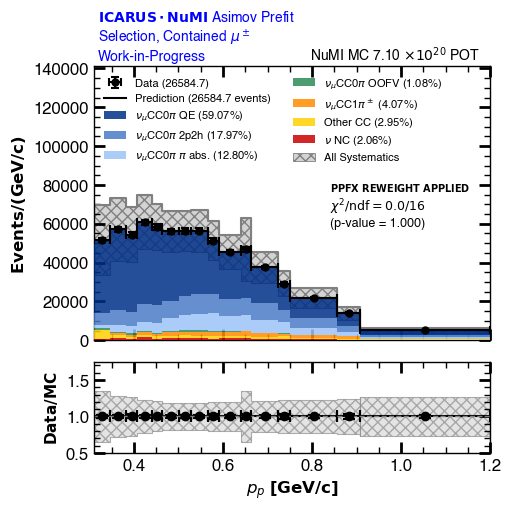

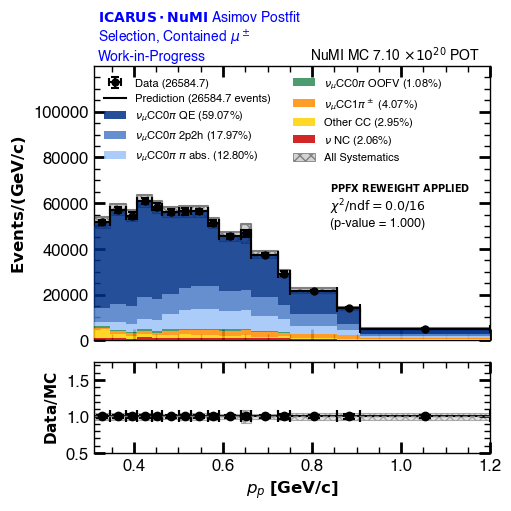

In [3]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_contained'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['selection_contained'],
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Prefits', save_name='prefit_proton_momentum_selection_contained',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_contained'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['selection_contained'],
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Postfits', save_name='postfit_proton_momentum_selection_contained'
)

## Selection - Exiting

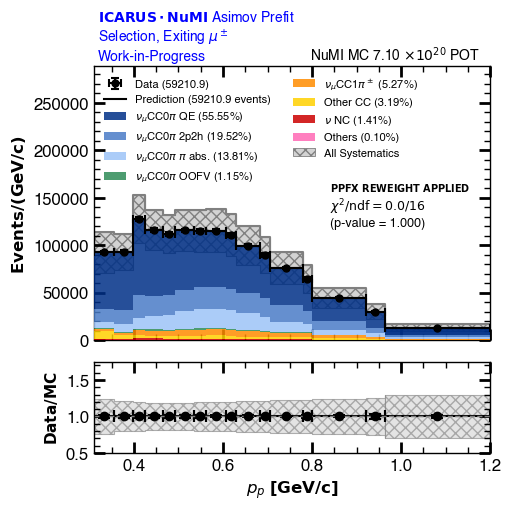

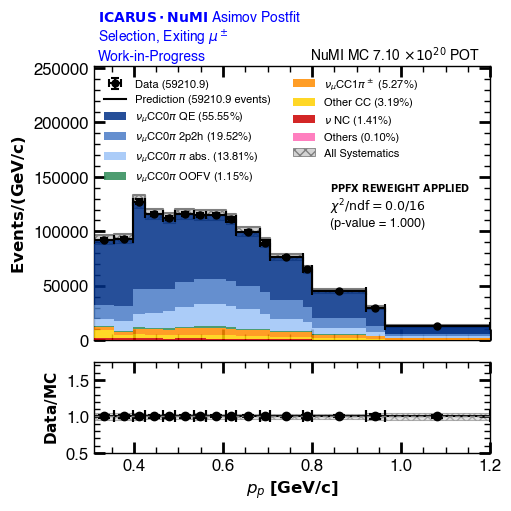

In [4]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_exiting'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['selection_exiting'],
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Prefits', save_name='prefit_proton_momentum_selection_exiting',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['selection_exiting'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['selection_exiting'],
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Postfits', save_name='postfit_proton_momentum_selection_exiting'
)

## Sideband - Contained

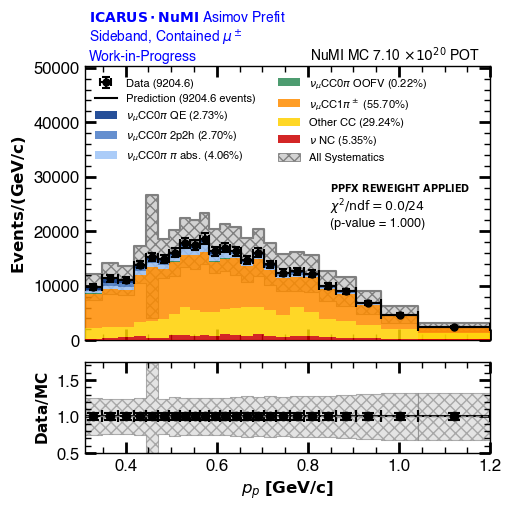

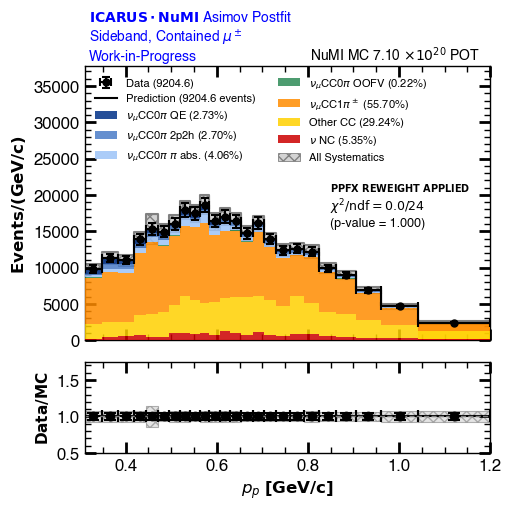

In [5]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_contained'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['sideband_contained'],
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Prefits', save_name='prefit_proton_momentum_sideband_contained',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_contained'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['sideband_contained'],
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Postfits', save_name='postfit_proton_momentum_sideband_contained'
)

## Sideband - Exiting

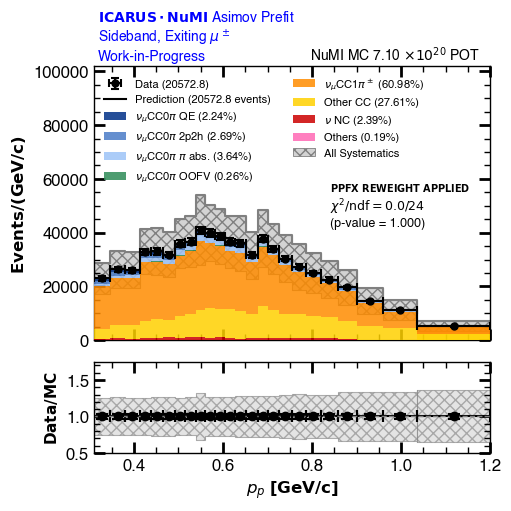

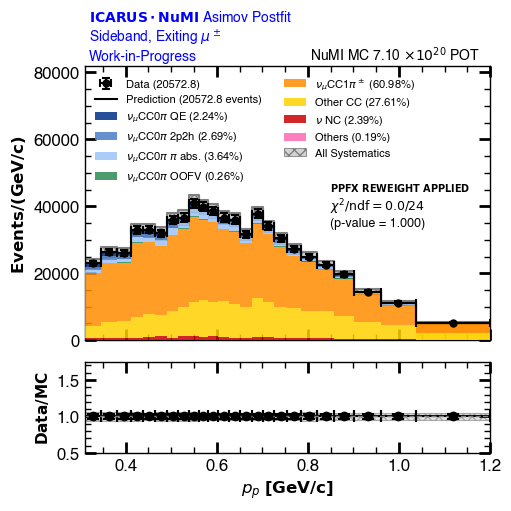

In [6]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=PREFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_exiting'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['sideband_exiting'],
    fit_type='pre-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Prefit' + '\n' + r'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Prefits', save_name='prefit_proton_momentum_sideband_exiting',
    pot=POT,
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path=POSTFIT_FILE,
    fitterengine_file_path=ASIMOV_FILE,
    sample_name=SAMPLES['sideband_exiting'],
    variable_name='reco_leading_proton_momentum',
    cov_bin_range=COV_RANGE['sideband_exiting'],
    fit_type='post-fit',
    xlabel=r'$p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\mathbf{Events / (GeV/c)}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Asimov Postfit' + '\n' + r'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=POT,
    save_dir=r'../Plots/proton_momentum/Asimov_Containment/Postfits', save_name='postfit_proton_momentum_sideband_exiting'
)

## Cross-Section Extraction

Extracted from `asimov_XSec_proton_momentum_containment.root` (CalcXsec run on the containment-fit output). It uses the true-level `True_proton_momentum_XS` sample with 8 finite truth bins plus one overflow bin, which the reco-level containment split does not change. The overflow bin is dropped from the plot (`remove_last_bin=True`, the default), so `TRUE_EDGES` has 9 edges for 8 plotted bins. The truth binning is in GeV/c, so the units are cm$^2$/((GeV/c) Ar), scaled by $10^{40}$. The manual calculation takes its bin widths in GeV/c with `energy_conversion=False`, and its built-in factor of $10^3$ is absorbed into `scaling_power_of_10=1e37`, so that $10^3 \times 10^{37} = 10^{40}$. The GENIE overlay divides by bin width in GeV/c and uses $10^{40}$ directly.


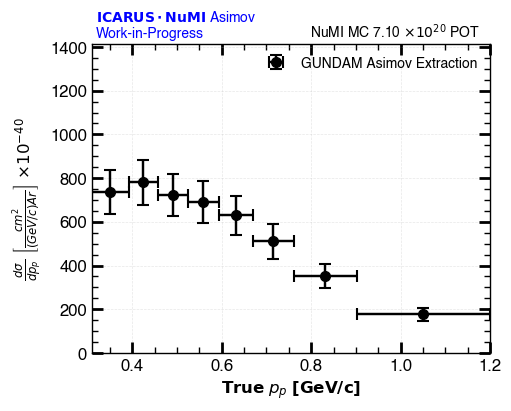

In [32]:
# Create the scatter plot and get the raw values
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
    filename=XSEC_FILE,
    is_cross_section=True,
    hist_path="calcXsec/histograms/True_proton_momentum_XS_TH1D;1",
    xlabel=r'$\mathbf{True}$ $p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\frac{d\sigma}{dp_{p}}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-40}$',
    bin_edges_labels=TRUE_EDGES,
    is_y_errors=True,
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    label="GUNDAM Asimov Extraction",
    pot=POT,
    scaling_power_of_10=1e40
)

save_fig(fig_xs, r'../Plots/proton_momentum/Asimov_Containment/XSection', 'proton_momentum_XS')


Signal Events and Cross-Section per True Bin
Bin Range (MeV/c)         N_Signal     Bin Width (MeV)    σ (x10^-40 cm²/GeV)
------------------------------------------------------------------------------------------
     0 - 0      MeV/c    15891        0                  7.375032e+02
     0 - 0      MeV/c    13081        0                  7.809117e+02
     0 - 1      MeV/c    12541        0                  7.228898e+02
     1 - 1      MeV/c    12466        0                  6.912019e+02
     1 - 1      MeV/c    12331        0                  6.300948e+02
     1 - 1      MeV/c    12291        0                  5.100004e+02
     1 - 1      MeV/c    12725        0                  3.521888e+02
     1 - 1      MeV/c    13555        0                  1.763893e+02
------------------------------------------------------------------------------------------
Total                     104881


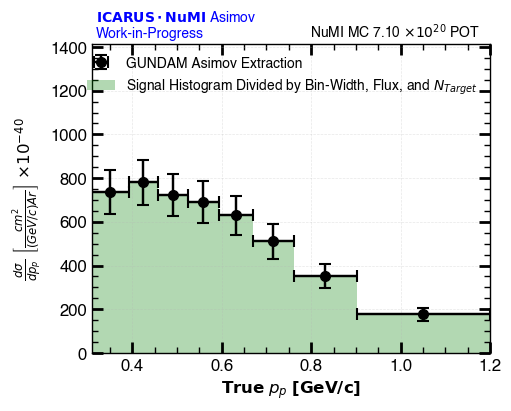

In [8]:
bins_gev = list(zip(TRUE_EDGES[:-1], TRUE_EDGES[1:]))   # 8 finite bins, GeV/c; the overflow bin is not plotted
# Overlay manual calculation -- unaffected by the containment split (true-level signal tree, no containment cut).
# overlay_manual_cross_section always multiplies by 1e3 (MeV -> GeV). The edges here are already in GeV/c,
# so scaling_power_of_10 is 1e37 (not 1e40) to give 1e3 * 1e37 = 1e40 per (GeV/c).
# energy_conversion=False keeps the bar positions and widths in GeV/c.
fig, ax, xs = overlay_manual_cross_section(
    fig=fig_xs,
    ax=ax_xs,
    signal_tree_path="events/full/signal",
    root_file_path=f"{SELECTION_DIR}/data/icarus_numi_numu_mc_onbeam_offbeam_syst_gundam.root",
    bins_mev=bins_gev,
    n_targets=4.721444e30,
    flux=5.1915e11,
    color='green',
    marker='s',
    label=r'Signal Histogram Divided by Bin-Width, Flux, and $N_{Target}$',
    variable_name="true_leading_proton_momentum",
    scaling_power_of_10=1e37,
    energy_conversion=False
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/XSection', 'proton_momentum_XS_wSignal')
display(fig)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           8.064178e+02
  0.3927 – 0.4571           8.069495e+02
  0.4571 – 0.5239           7.417047e+02
  0.5239 – 0.5934           7.011902e+02
  0.5934 – 0.6689           6.375049e+02
  0.6689 – 0.7620           5.133252e+02
  0.7620 – 0.9018           3.497182e+02
  0.9018 – 1.2000           1.766751e+02

χ² / Ndof = 0.6 / 8 = 0.073
p-value = 1.000


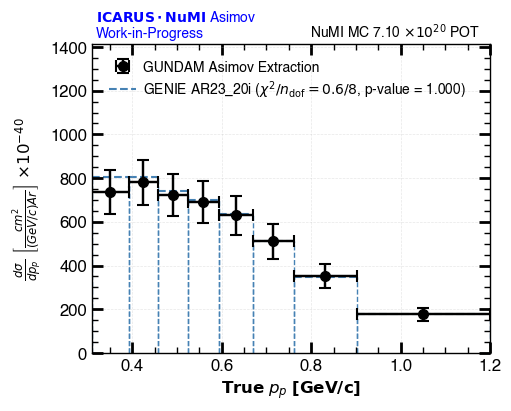

In [33]:
# Overlay GENIE with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu-14",
    bin_edges=TRUE_EDGES,
    nuisance_var='ICARUS_1muNp0pi_ProtonP',   # leading proton momentum in GeV/c in the NUISANCE flat tree
    scaling_power_of_10=1e40,                     # per (GeV/c), same units as the GUNDAM points above
    label='GENIE AR23_20i',
    extracted_xsec=xsec_extracted,
    extracted_xsec_errors=xsec_extracted_errors,
    add_ratio=False,
    draw_extracted_ratio=False,
)

save_fig(fig_genie, r'../Plots/proton_momentum/Asimov_Containment/XSection', 'proton_momentum_XS_wGENIE')
display(fig_genie)

## Template Parameter Post-fit Values

One set of 9 template parameters (8 finite bins plus the overflow bin), shared across all four samples in the joint fit -- not split by containment. The overflow parameter is not drawn: `plot_scatter` drops the last bin by default.

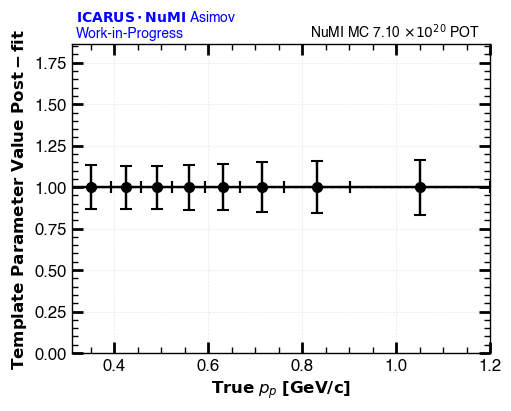

In [10]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename=ASIMOV_FILE,
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_leading_proton_momentum/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $p_{p}$ $\mathbf{[GeV/c]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=TRUE_EDGES,
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=POT
)
save_fig(fig_template, r'../Plots/proton_momentum/Asimov_Containment/TemplateParameters', 'proton_momentum')

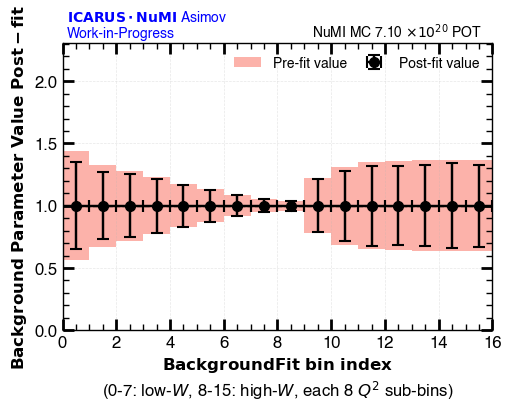

In [11]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename=ASIMOV_FILE,
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=POT,
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/proton_momentum/Asimov_Containment/BackgroundFitParameters', 'proton_momentum')

## Nuisance Parameter Constraints

Pre-fit/post-fit constraint plots for the interaction-model, flux, and detector systematics. These dial sets do not depend on the observable or on the reco-level split (`applyOnDataSets` is keyed by dataset name, not fitSample name), so this is one set of plots for the whole joint fit. The G4 sets are the proton-momentum versions, whose covariances are binned in reco $p_p$ (17 parameters each, contained and exiting).

Number of parameters: 52


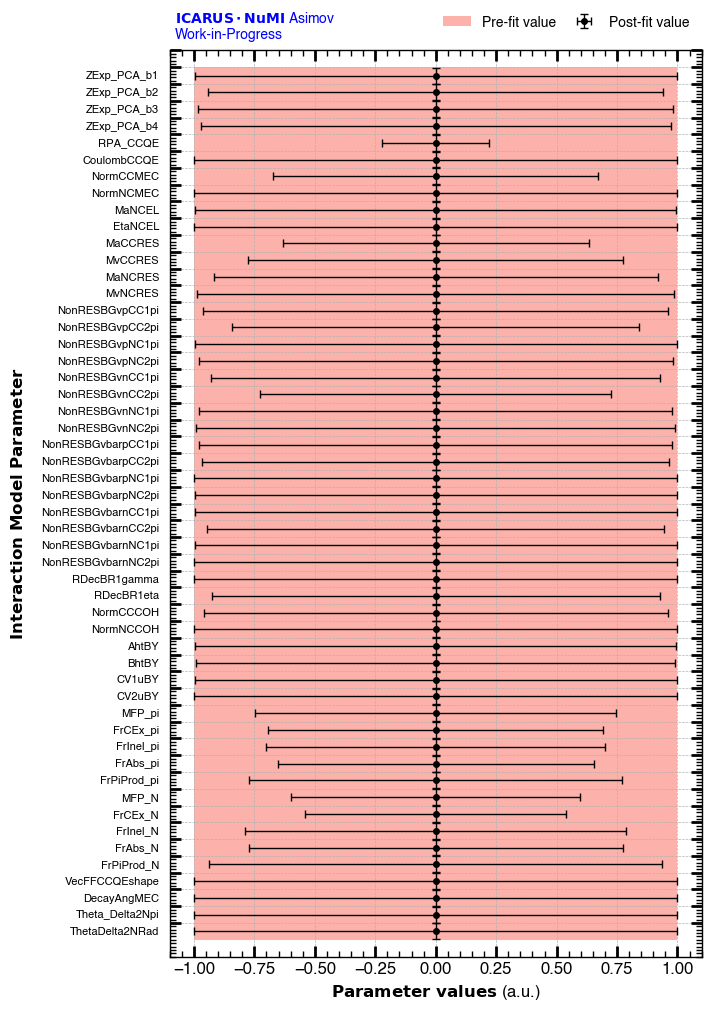

In [12]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 10),
    y_label=r'$\mathbf{Interaction\ Model\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_InteractionModel')

Number of parameters: 27


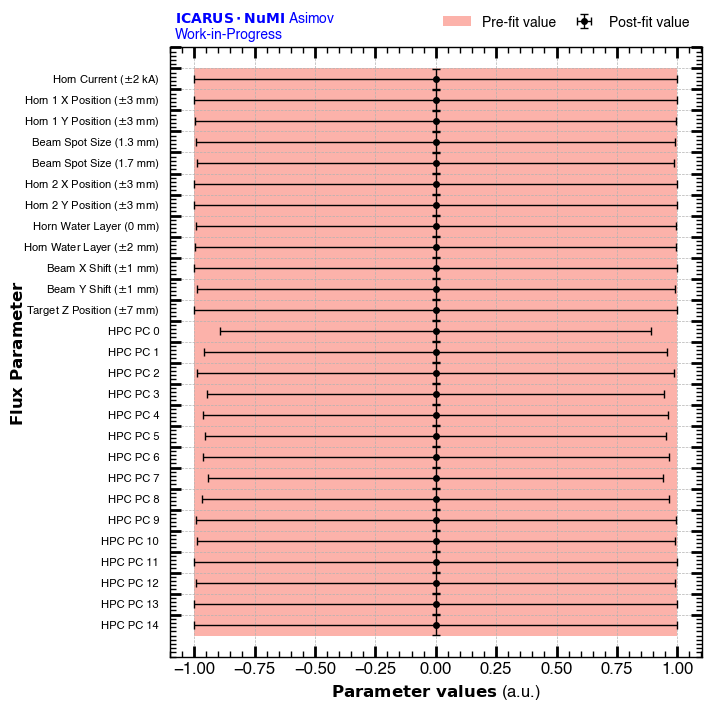

In [13]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 7),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_Flux')

Number of parameters: 9


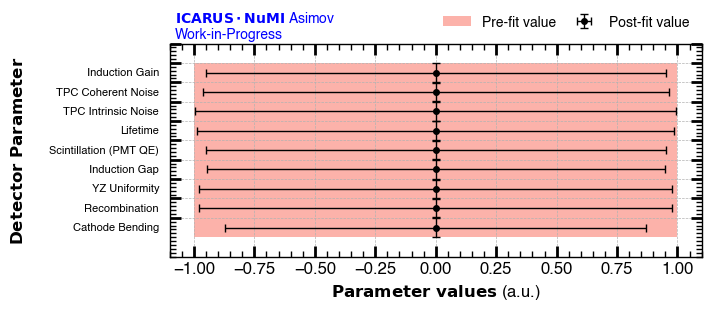

In [14]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_Detector')

Number of parameters: 17


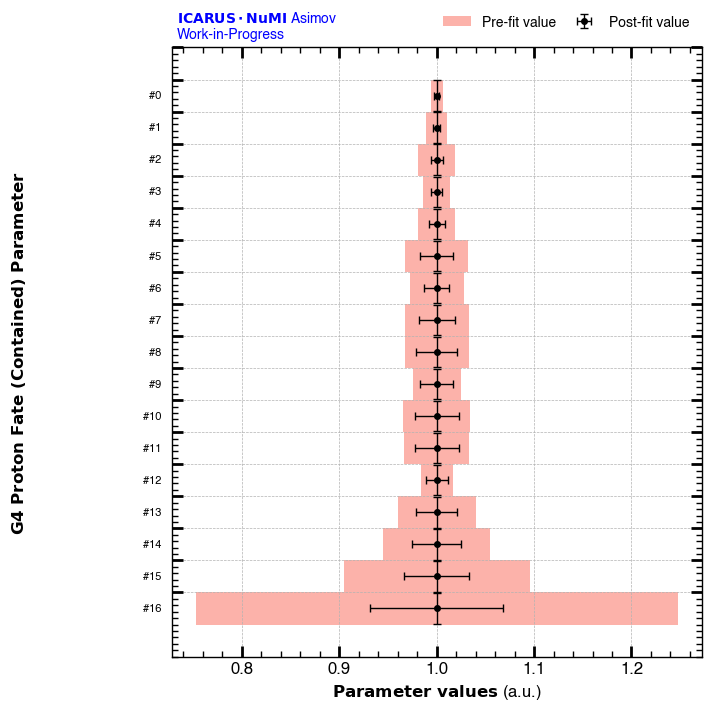

In [15]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (proton momentum, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_G4_Proton_Contained')

Number of parameters: 17


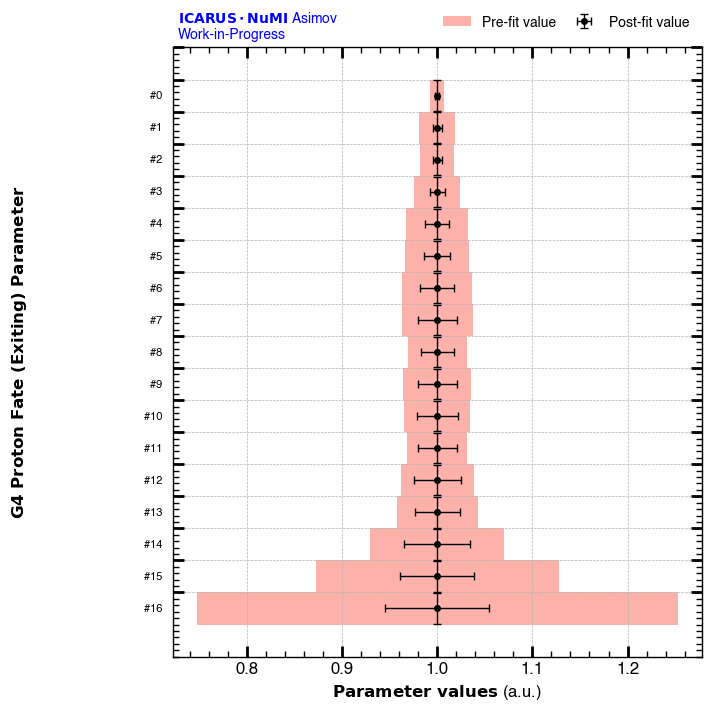

In [16]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (proton momentum, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_G4_Proton_Exiting')

Number of parameters: 17


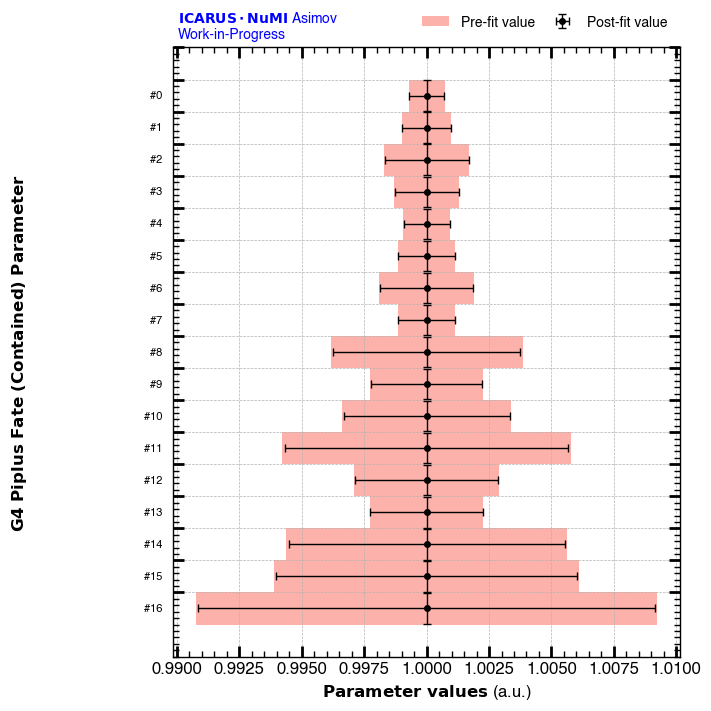

In [17]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (proton momentum, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_G4_Piplus_Contained')

Number of parameters: 17


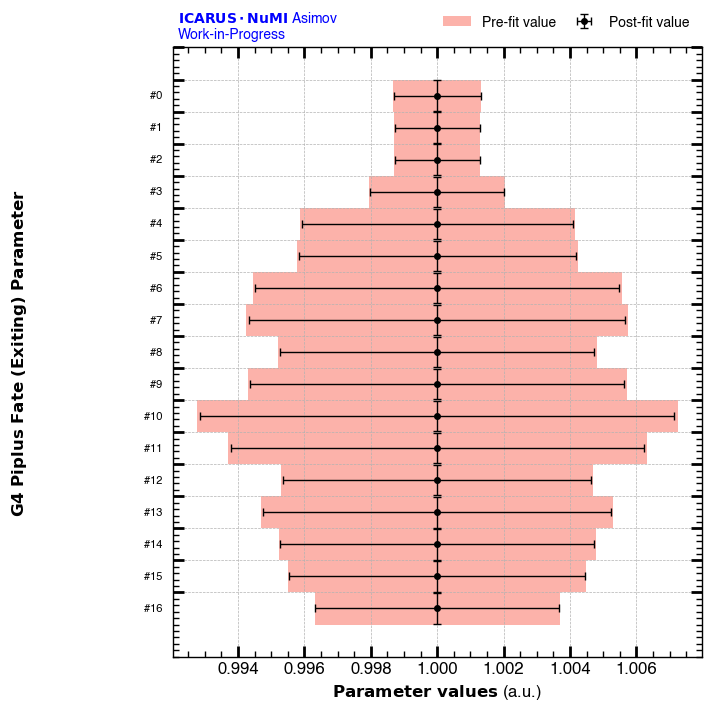

In [18]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (proton momentum, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_G4_Piplus_Exiting')

Number of parameters: 17


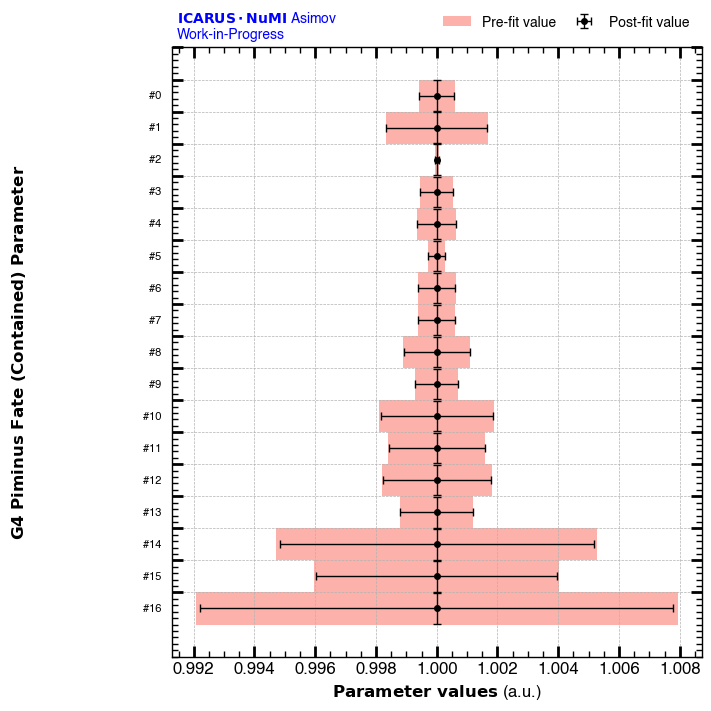

In [19]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (proton momentum, contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_G4_Piminus_Contained')

Number of parameters: 17


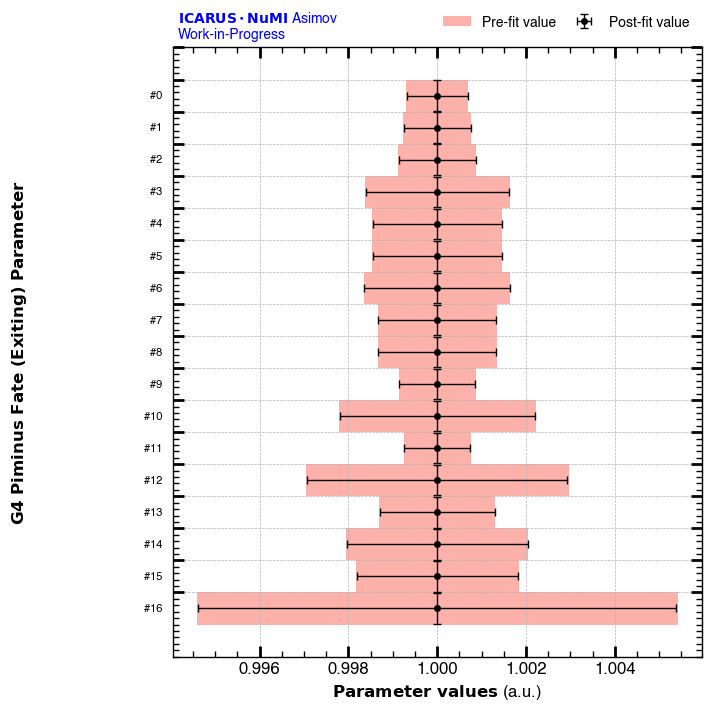

In [20]:
fig, ax = plot_fit_constraints(
    filename=ASIMOV_FILE,
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (proton momentum, exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/proton_momentum/Asimov_Containment/NuisanceParameters', 'proton_momentum_G4_Piminus_Exiting')

## Covariance / Correlation Matrices

Per-systematic-block matrices (interaction model, flux, detector, G4) -- these are among the nuisance parameters themselves, not among reco bins, so `bin_range` is left at its default (full block). Not to be confused with the reco-bin covariance used inside `plot_gundam_stacked`'s chi2 calculation, which is a different matrix (`toyGen/matrices/covarianceMatrix_TH2D`).

Full matrix size: 52×52


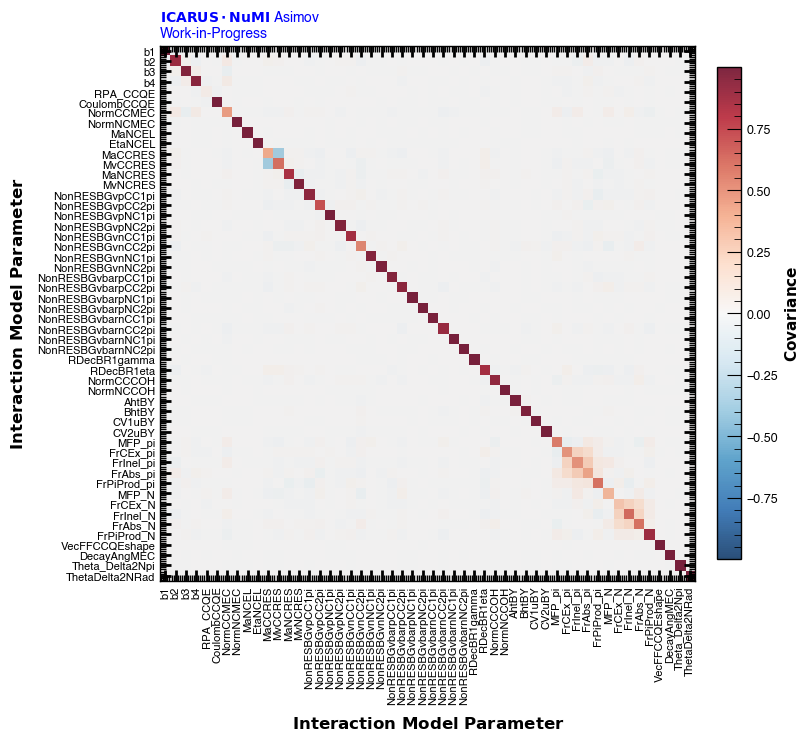

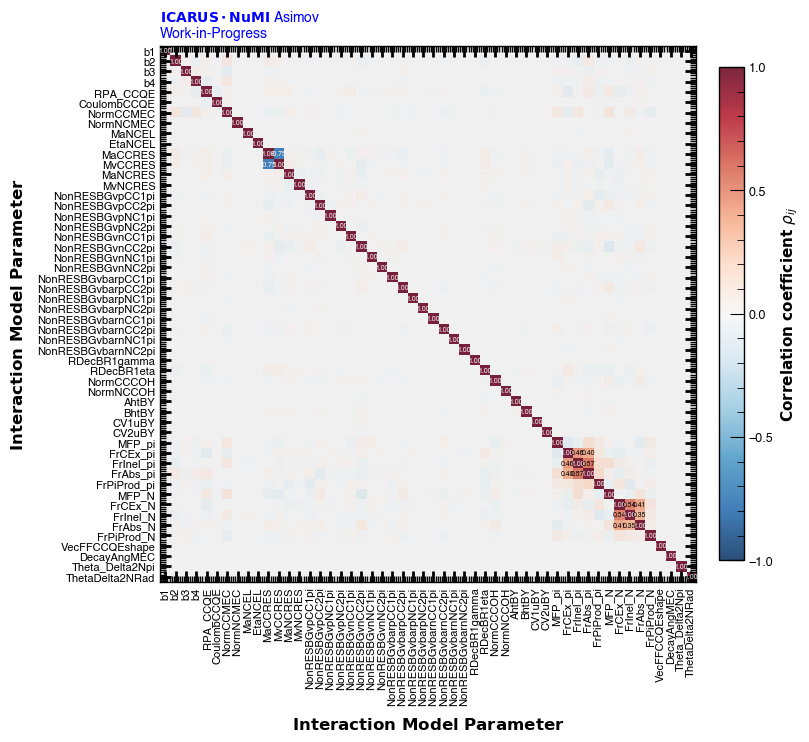

In [21]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(8, 20),
    label_name=r"$\mathbf{Interaction\ Model\ Parameter}$",
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


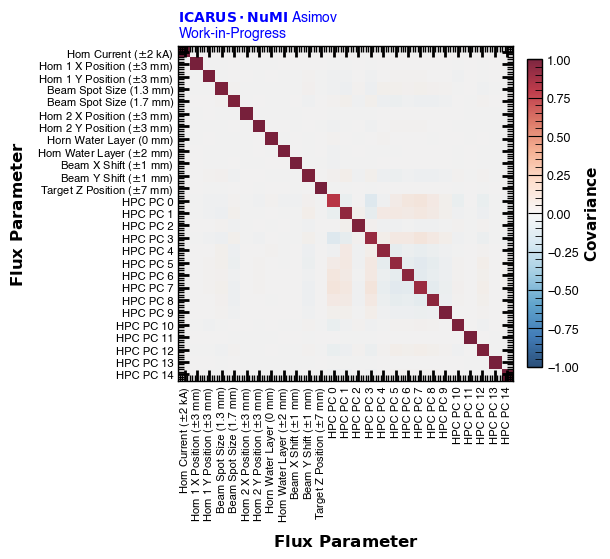

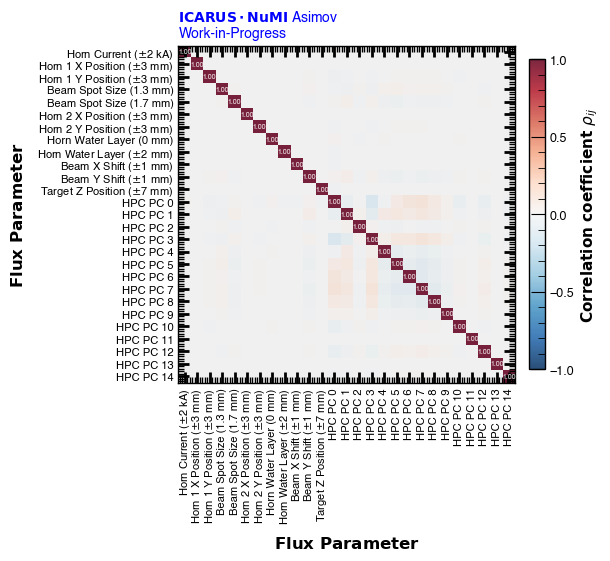

In [22]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


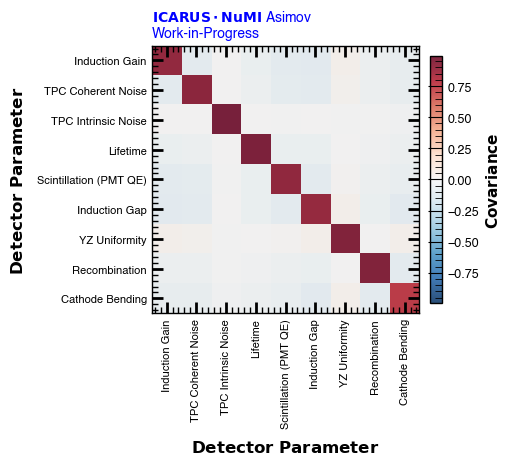

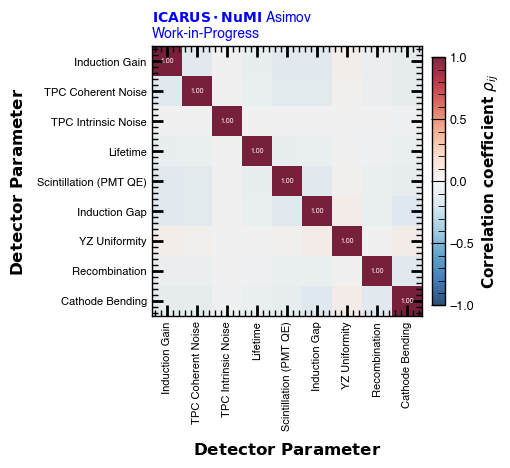

In [23]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'detector_param_correlation')

Full matrix size: 17×17


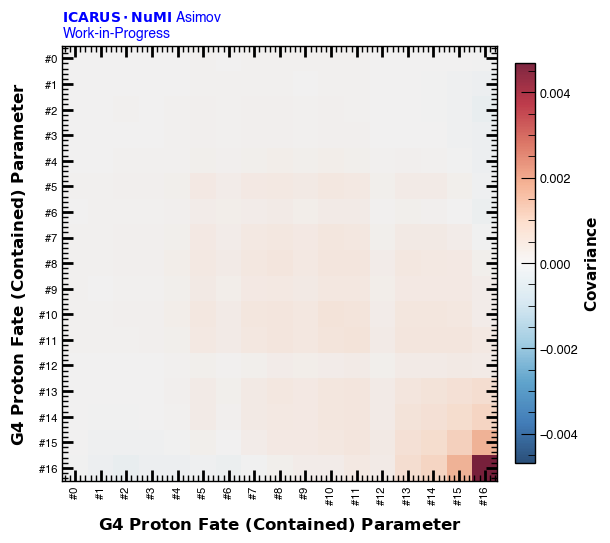

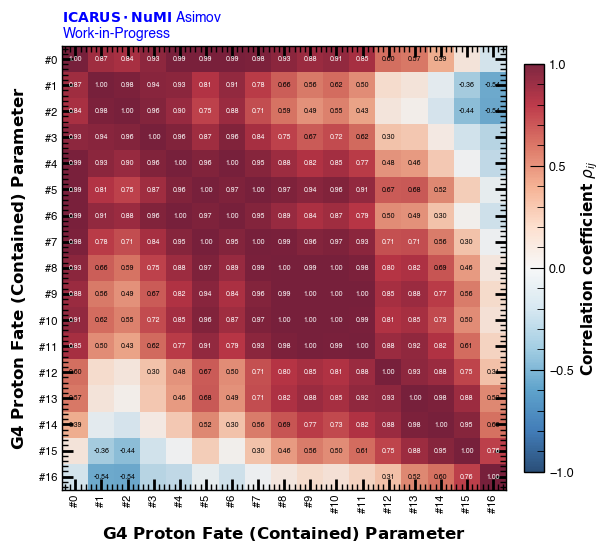

In [24]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (proton momentum, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (proton momentum, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_proton_contained_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_proton_contained_param_correlation')

Full matrix size: 17×17


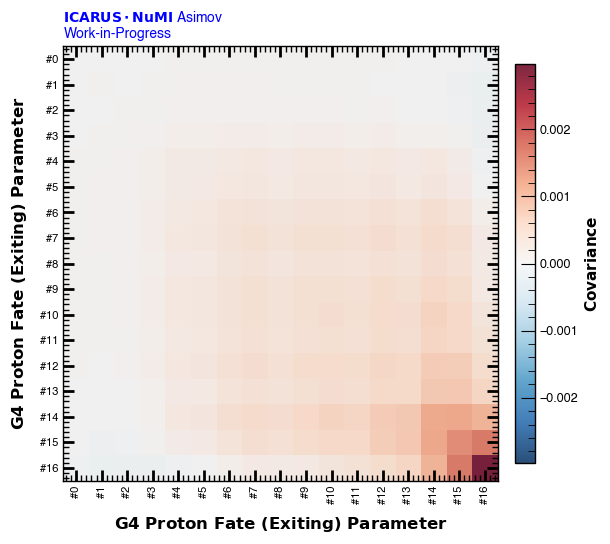

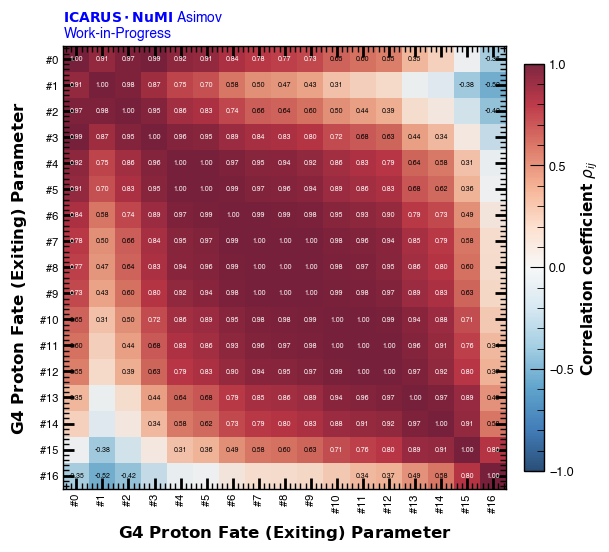

In [25]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (proton momentum, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (proton momentum, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_proton_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_proton_exiting_param_correlation')

Full matrix size: 17×17


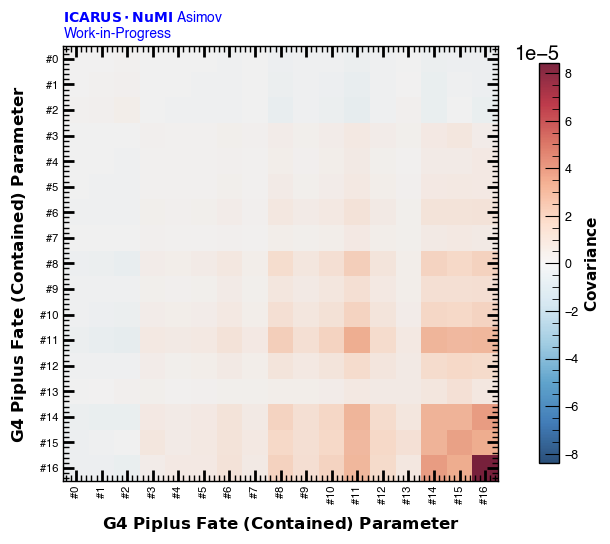

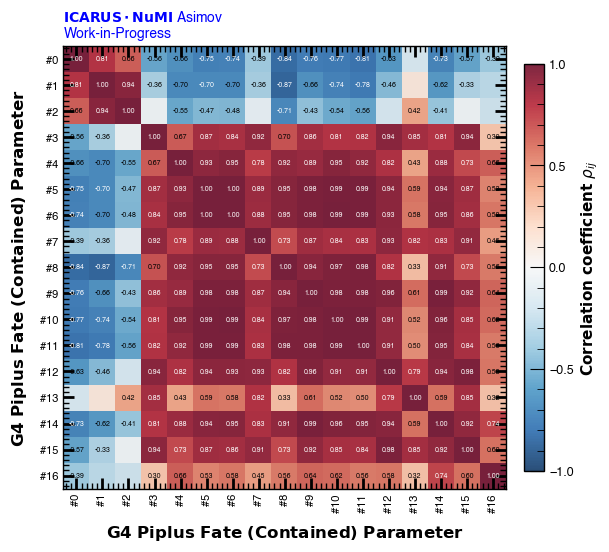

In [26]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (proton momentum, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (proton momentum, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piplus_contained_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piplus_contained_param_correlation')

Full matrix size: 17×17


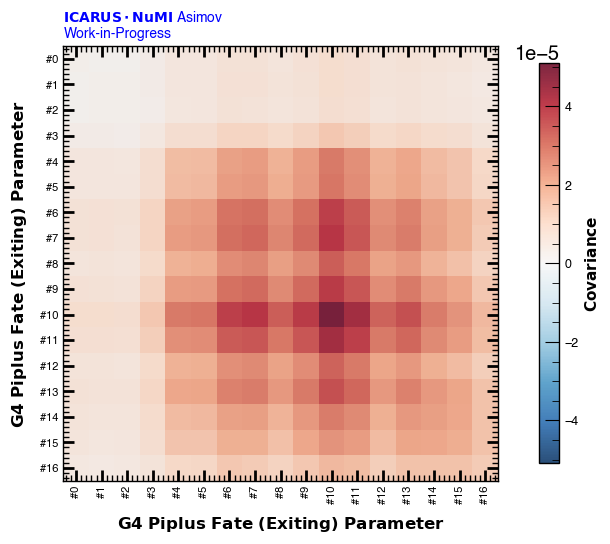

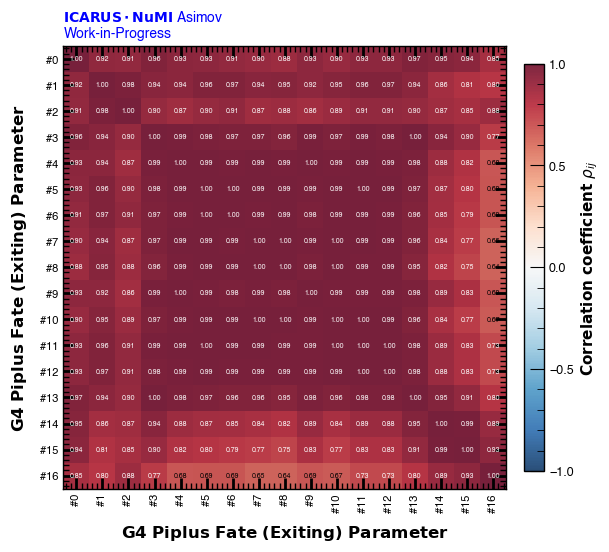

In [27]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (proton momentum, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (proton momentum, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piplus_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piplus_exiting_param_correlation')

Full matrix size: 17×17


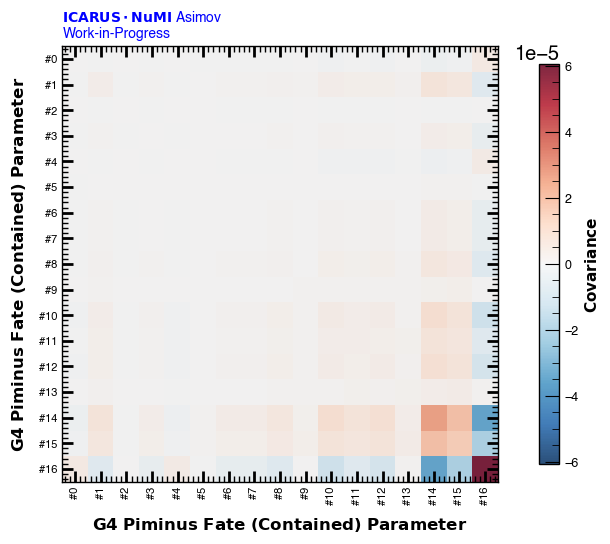

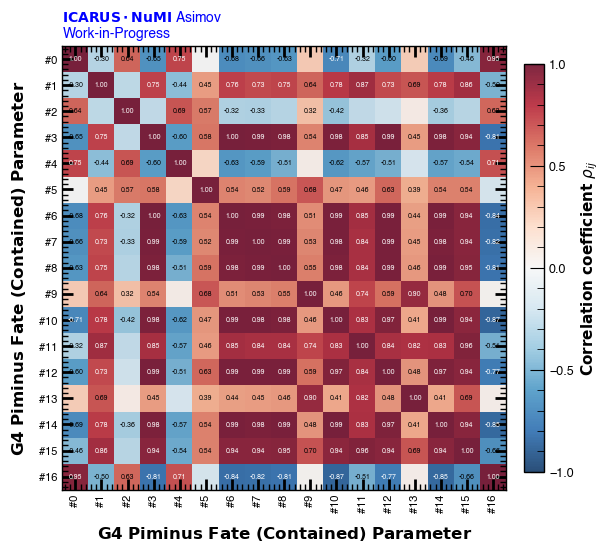

In [28]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (proton momentum, contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (proton momentum, contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piminus_contained_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piminus_contained_param_correlation')

Full matrix size: 17×17


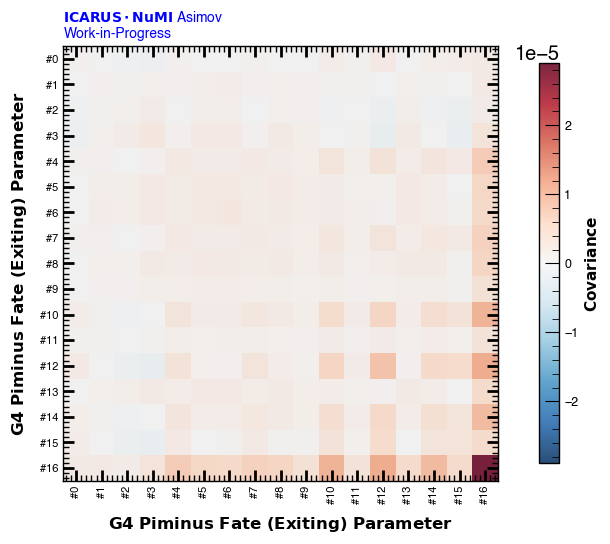

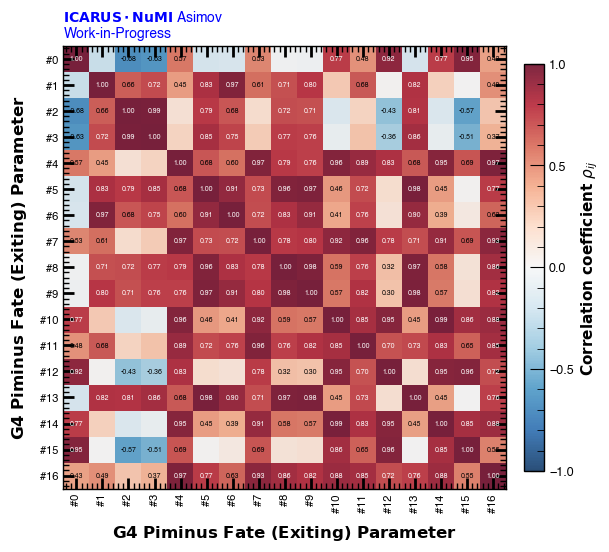

In [29]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(6, 12),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (proton momentum, exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (proton momentum, exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piminus_exiting_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'g4_piminus_exiting_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large for per-cell values to be legible.

Full matrix size: 158×158


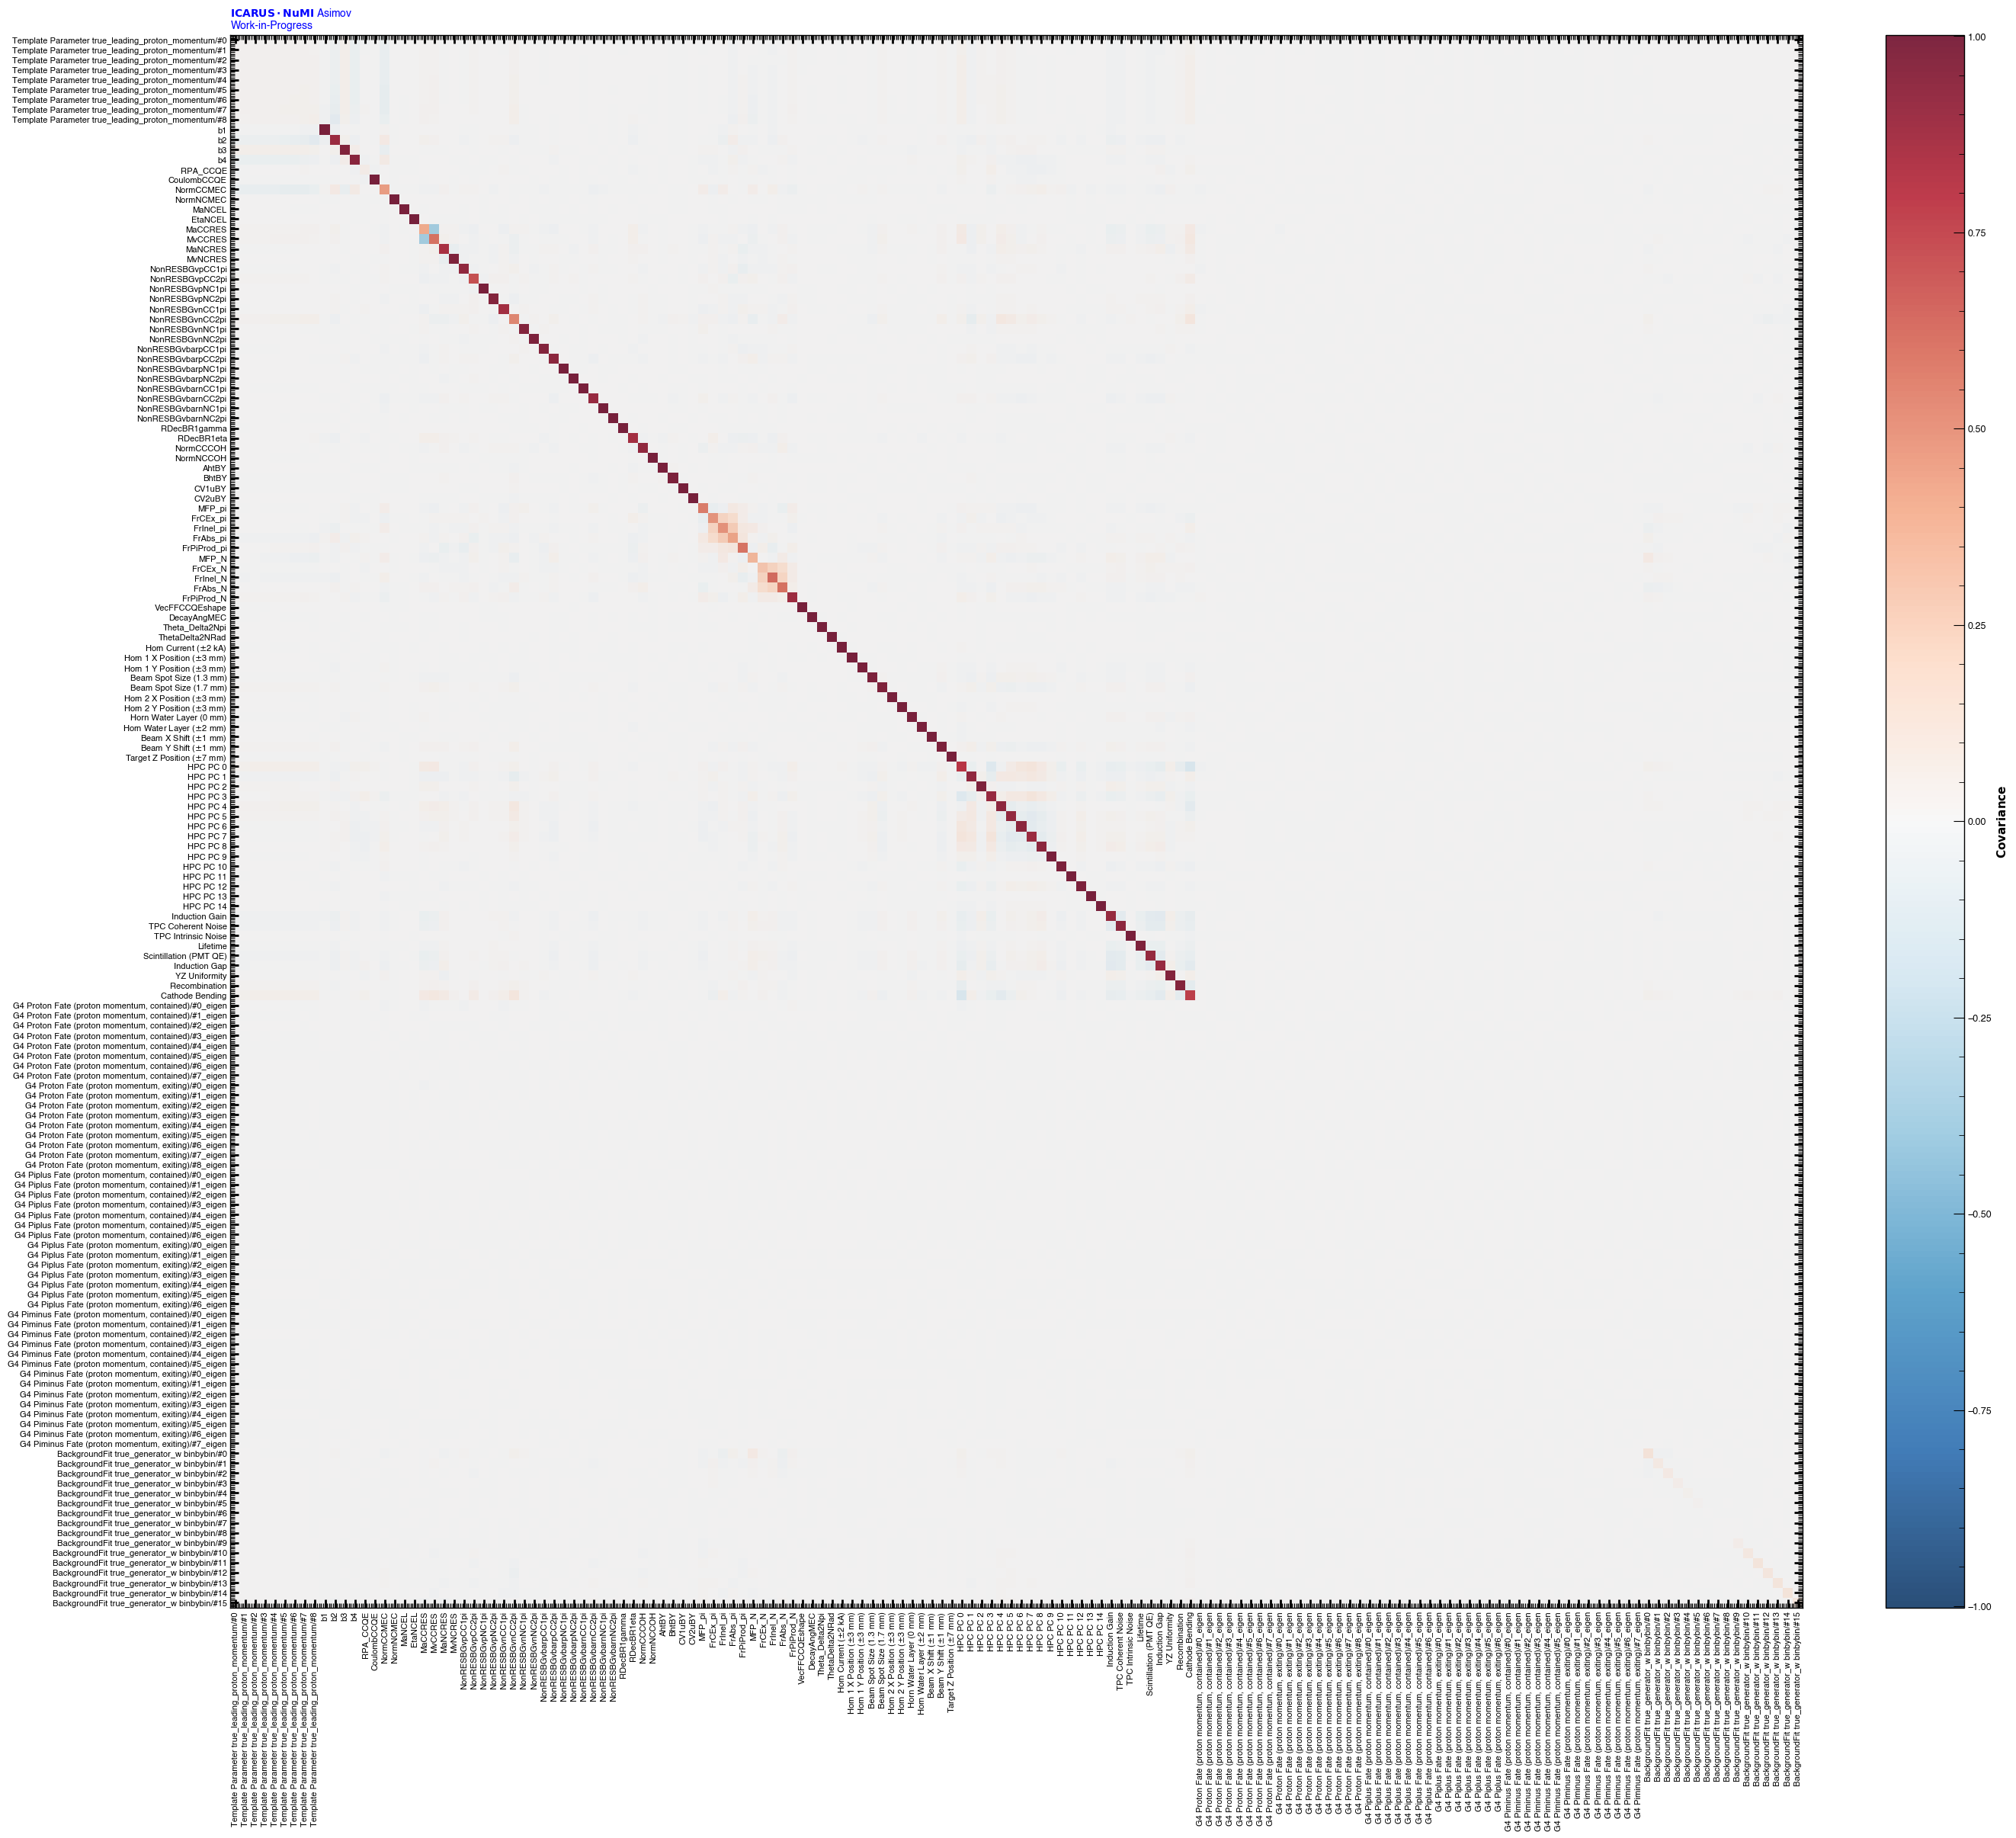

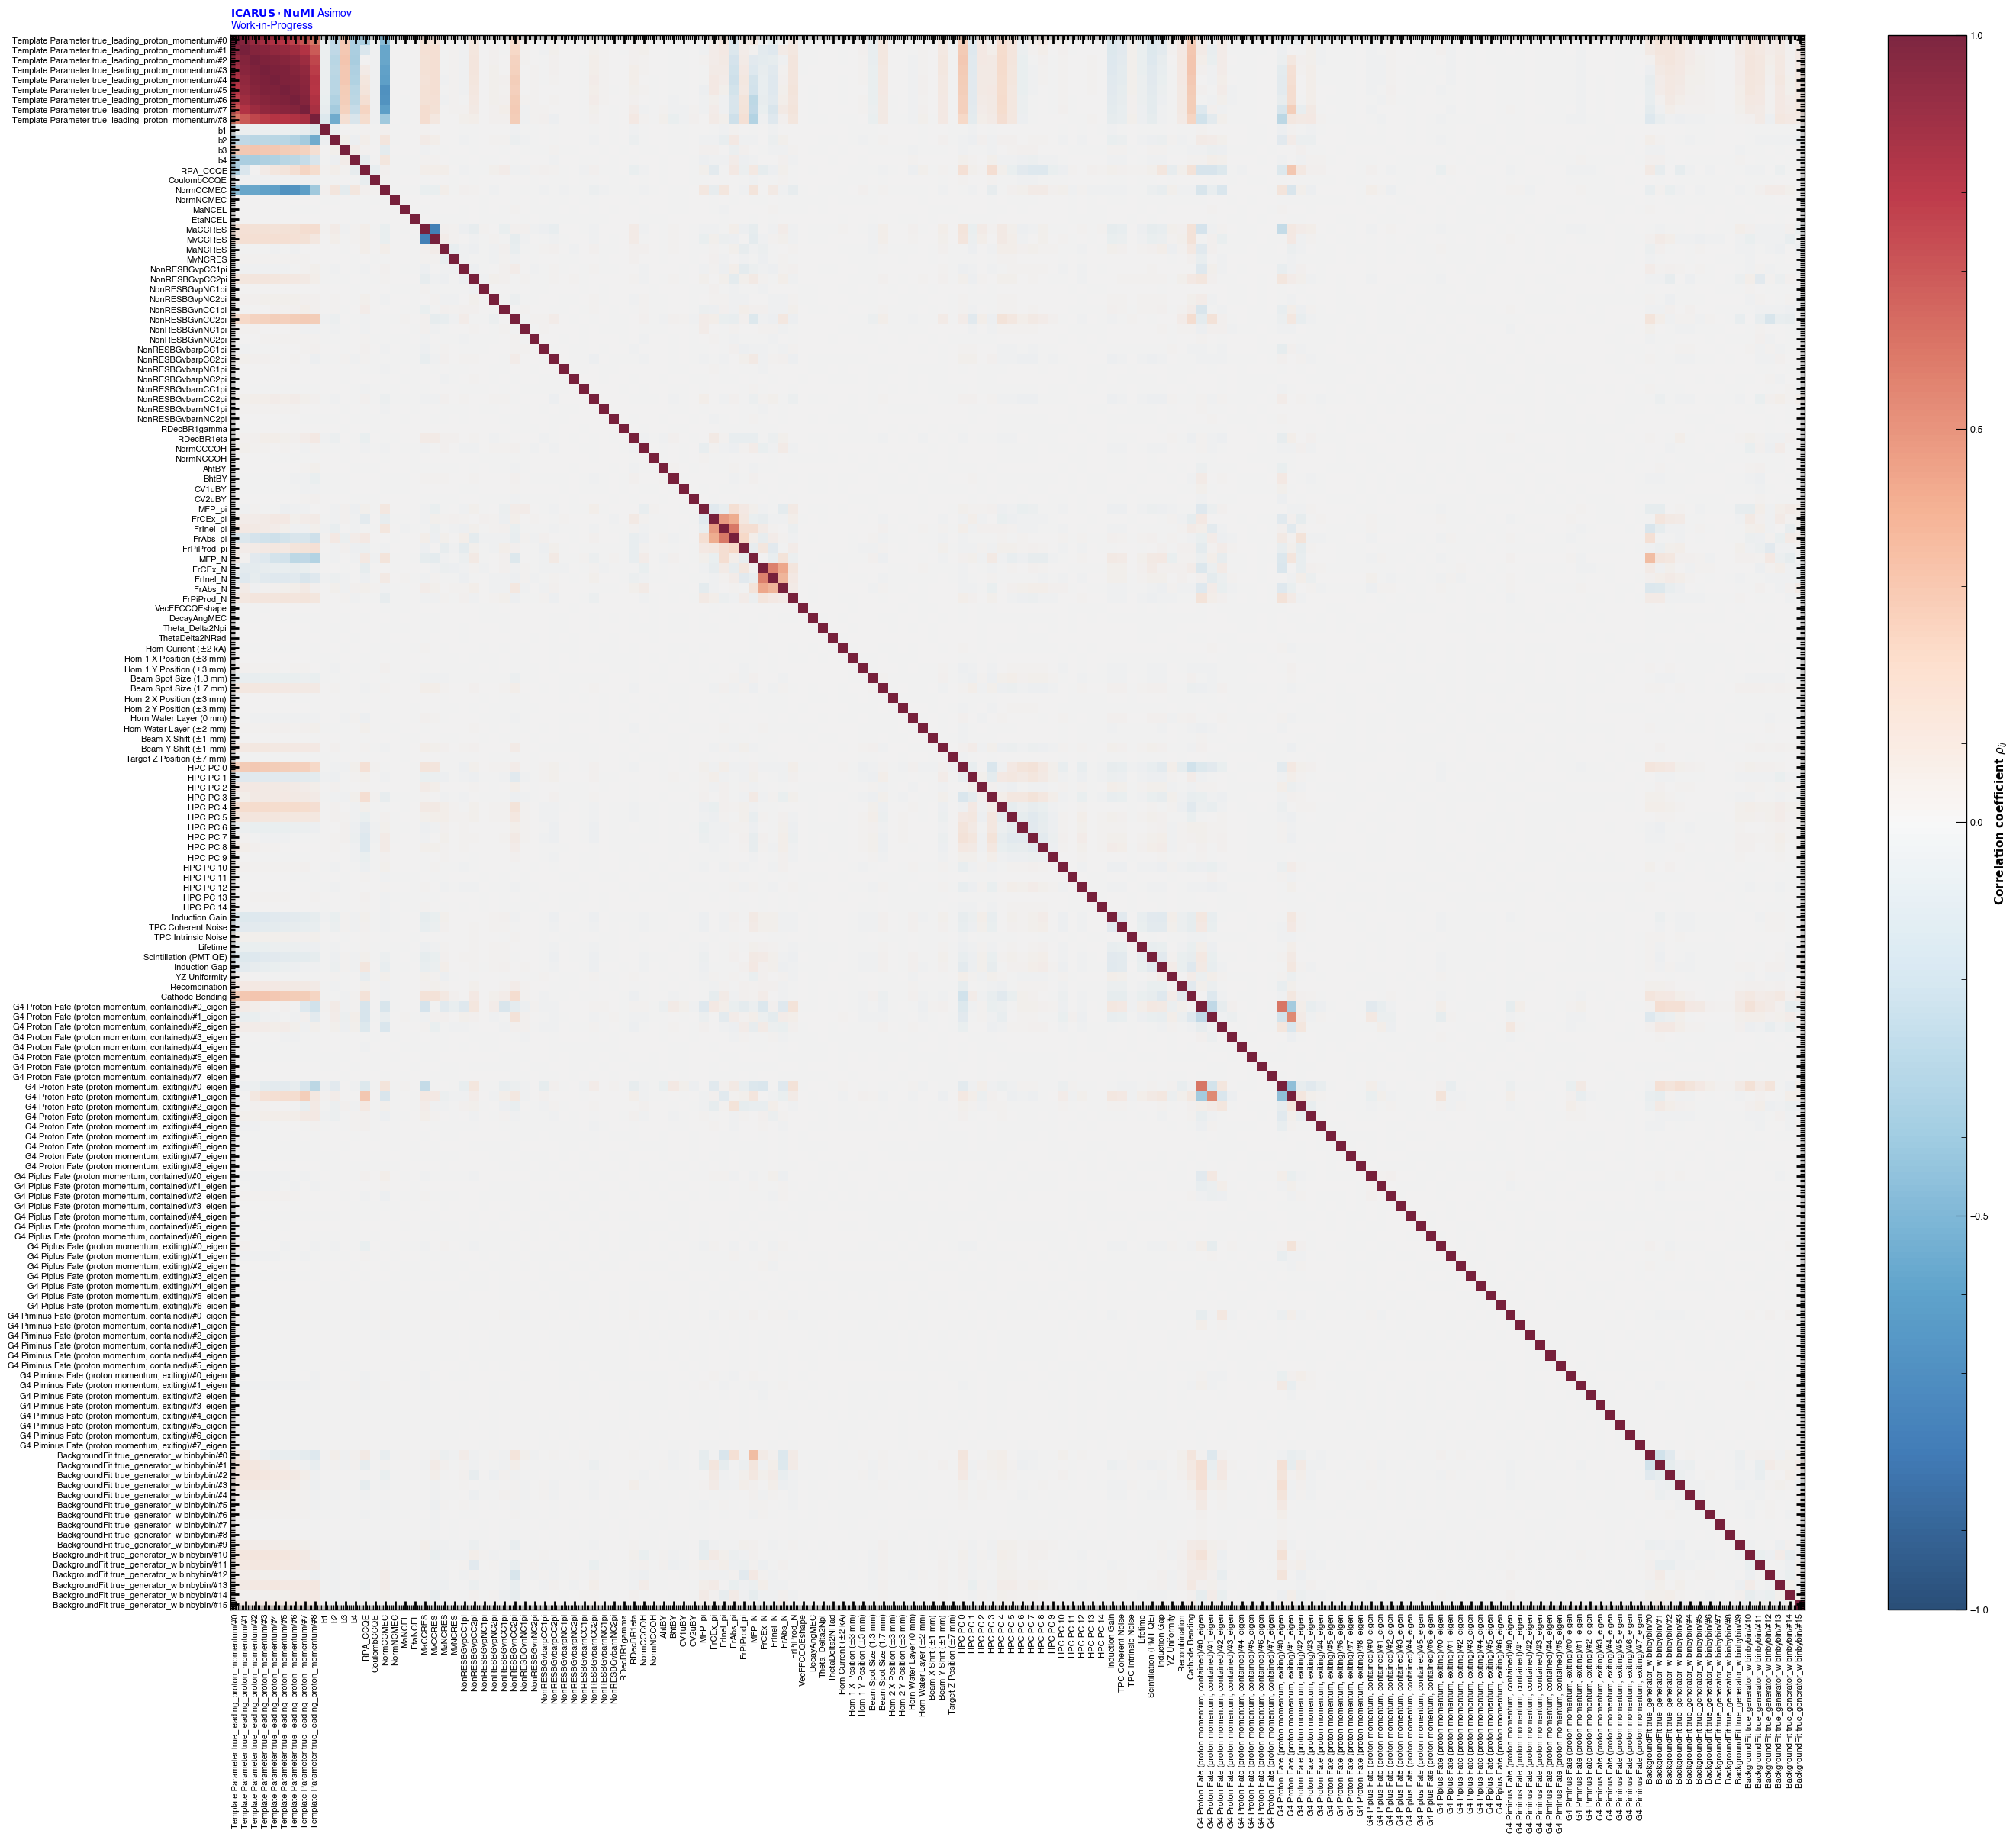

In [30]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_leading_proton_momentum",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate (proton momentum, contained)",
    "G4 Proton Fate (proton momentum, exiting)",
    "G4 Piplus Fate (proton momentum, contained)",
    "G4 Piplus Fate (proton momentum, exiting)",
    "G4 Piminus Fate (proton momentum, contained)",
    "G4 Piminus Fate (proton momentum, exiting)",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    ASIMOV_FILE,
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Asimov' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
)
save_fig(fig_cov, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'../Plots/proton_momentum/Asimov_Containment/Postfits', 'all_param_correlation')


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           0.000000e+00
  0.3927 – 0.4571           7.066209e+02
  0.4571 – 0.5239           7.339826e+02
  0.5239 – 0.5934           6.938961e+02
  0.5934 – 0.6689           6.307925e+02
  0.6689 – 0.7620           5.075548e+02
  0.7620 – 0.9018           3.451662e+02
  0.9018 – 1.2000           7.707952e+01

GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_ProtonP)
Bin range                                 xsec
----------------------------------------------------------------------
  0.3100 – 0.3927           0.000000e+00
  0.3927 – 0.4571           7.066209e+02
  0.4571 – 0.5239           7.339826e+02
  0.5239 – 0.5934           6.938961e+02
  0.5934 – 0.6689           6.307925e+02
  0.6689 – 0.7620           5.075548e+02
  0.7620 – 0.9018           3.451662e+02
  0.9018 – 1.2000           7.707952e

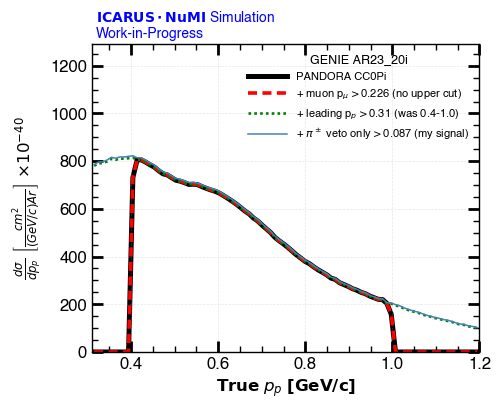

In [5]:
# GENIE cross section: signal definition morphing from Howard's to mine
import matplotlib.pyplot as plt
# Same axes/format as the other cross-section plots (plot_scatter), with the
# GUNDAM points removed so only the GENIE curves are shown.
fig_mor, ax_mor, _, _ = plot_scatter(
    filename=XSEC_FILE,
    is_cross_section=True,
    hist_path="calcXsec/histograms/True_proton_momentum_XS_TH1D;1",
    xlabel=r'$\mathbf{True}$ $p_{p}$ $\mathbf{[GeV/c]}$',
    ylabel=r'$\frac{d\sigma}{dp_{p}}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-40}$',
    bin_edges_labels=TRUE_EDGES,
    is_y_errors=True,
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Simulation' + '\n' + 'Work-in-Progress',
    label=None,
    pot='',
    scaling_power_of_10=1e40
)
# drop the GUNDAM extraction, keep the frame, ticks, title and labels
for art in list(ax_mor.lines) + list(ax_mor.collections):
    art.remove()
ax_mor.containers.clear()

steps = [
    ('ICARUS_1muNp0pi_IsSignal_muonChanged',        "PANDORA CC0Pi",                      'black'),
    ('ICARUS_1muNp0pi_IsSignal_muonChanged',   "+ muon p$_\\mu$ > 0.226 (no upper cut)", 'red'),
    ('ICARUS_1muNp0pi_IsSignal_protonChanged', "+ leading p$_p$ > 0.31 (was 0.4-1.0)",  'green'),
    ('ICARUS_1muNp0pi_IsSignal',               "+ $\\pi^\\pm$ veto only > 0.087 (my signal)", 'steelblue'),
]

# Line styles in draw order. Overlapping models stay distinguishable because the first is the
# thickest and solid, and each later one is thinner and drawn on top with a different dash pattern.
LINE_STYLES = [
    dict(linewidth=3.6, linestyle='-',             zorder=1),   # baseline: thick, solid, underneath
    dict(linewidth=2.6, linestyle=(0, (2.5, 1.5)), zorder=2),   # dashed
    dict(linewidth=1.9, linestyle=(0, (1.0, 1.2)), zorder=3),   # dotted
    dict(linewidth=1.1, linestyle='-',             zorder=4),   # thin solid on top
]

ymax = 0
for (branch, lab, col), sty in zip(steps, LINE_STYLES):
    _, _, xs, _ = overlay_genie_nuisance_xsec(
        fig_mor, ax_mor,
        nuisance_file_dir=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu14",
        nuisance_file_dir_numubar=f"{GUNDAM_DIR}/data/Generators/GENIE/fhc_Nu-14",
        bin_edges=TRUE_EDGES,
        nuisance_var='ICARUS_1muNp0pi_ProtonP',
        signal_expr=f'{branch} == True',
        scaling_power_of_10=1e40,
        label=lab, color=col,
        **sty,
        finer_binning=True,    # smooth curve on a fine grid instead of steps on the analysis bins
        n_fine_bins=90,        # 0.31-1.2 GeV/c in ~0.01 GeV/c bins
        add_ratio=False,
    )
    ymax = max(ymax, float(max(xs)))

new_ymax = ymax * 1.6
ax_mor.set_ylim(0, new_ymax)

# plot_scatter placed the title/POT text above the *old* y-range; move them
# to just above the frame of the new one
for t in ax_mor.texts:
    t.set_position((t.get_position()[0], new_ymax + 0.01 * new_ymax))

# legend: steps in order, inside the frame (upper right, where the curves are low)
handles, labels = ax_mor.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
order = [lab for _, lab, _ in steps]
ax_mor.legend([by_label[o] for o in order], order, loc='upper right',
              handlelength=3.5, fontsize=8, title='GENIE AR23_20i', title_fontsize=9, framealpha=0.8)

save_fig(fig_mor, r'../Plots/proton_momentum/Asimov_Containment/XSection', 'proton_momentum_XS_GENIE_signal_morphing')
plt.close(fig_mor)   # avoid the inline backend drawing the figure a second time
display(fig_mor)